In [1]:
import pandas as pd

# Splits saved at the end of 03_split.ipynb
train = pd.read_parquet('../data/processed/train.parquet')
val = pd.read_parquet('../data/processed/val.parquet')
test = pd.read_parquet('../data/processed/test.parquet')

# Raw side-information files
customers = pd.read_parquet('../data/RAW/customers.parquet')
articles = pd.read_parquet('../data/RAW/articles.parquet')

# Lookup table from Day 1: customer_id (text) <-> customer_join_idx (number)
# needed in Step 2, because customers has text ids but train has numbers
customer_lookup = pd.read_parquet('../data/processed/customer_join_idx.parquet')

In [2]:
# A: fix the spelling upstream, once, for ALL customers: 'None' and 'NONE' mean the same thing
none_before = (customers['fashion_news_frequency'] == 'NONE').sum()
customers['fashion_news_frequency'] = customers['fashion_news_frequency'].replace('None', 'NONE')
none_after = (customers['fashion_news_frequency'] == 'NONE').sum()

assert none_after == none_before + 2, f'expected NONE to grow by 2, got {none_before:,} -> {none_after:,}'
assert (customers['fashion_news_frequency'] == 'None').sum() == 0, "'None' should be gone"
print('NONE:', none_before, '->', none_after)

NONE: 877711 -> 877713


**Spelling rule (serving time too):** this is a rule, not a one-off fix. On Day 16 the API must apply the same `'None' -> 'NONE'` replacement to a new customer's value *before* the vocabulary lookup, otherwise that customer silently maps to 0 (unknown).

## Names used in this notebook (cheat sheet)
| Name | What it is |
|---|---|
| `train`, `val`, `test` | purchase tables from `03_split.ipynb` (weeks 0-9, 10, 11) |
| `customers` | raw customers file + `customer_join_idx` column (spelling fixed) |
| `articles` | raw articles file |
| `customer_lookup` | Day 1 table: `customer_id` (text) <-> `customer_join_idx` (number) |
| `train_customers` | customers who bought something in train (444,431) |
| `train_articles` | articles bought in train (38,603) |
| `age_buckets` | each train customer's age bucket (Step 7), `edges` = the cut points |
| `build_vocab(column)` | value -> number 1..N, 0 = unknown |
| `customer_vocab`, `article_vocab` | ID mappings (Steps 8-9) |
| `vocabs` | dict of category vocabularies, e.g. `vocabs['colour_group_name']` (Step 10) |
| `article_median_price` | median price per train article |
| `type_median_price`, `overall_median_price` | fallback prices for cold articles |
| `FEATURES_FOLDER` | where everything is saved: `../data/processed/features/` |

In [3]:
print('train:    ', train.shape)
print('val:      ', val.shape)
print('test:     ', test.shape)
print('customers:', customers.shape)
print('articles: ', articles.shape)
print('lookup:   ', customer_lookup.shape)

train:     (2638103, 6)
val:       (230980, 6)
test:      (216792, 6)
customers: (1371980, 7)
articles:  (105542, 25)
lookup:    (1371980, 2)


In [4]:
# Predictions turned into checks
assert train.shape == (2_638_103, 6), f'train shape {train.shape}'
assert val.shape == (230_980, 6), f'val shape {val.shape}'
assert test.shape == (216_792, 6), f'test shape {test.shape}'
assert customers.shape == (1_371_980, 7), f'customers shape {customers.shape}'
assert articles.shape == (105_542, 25), f'articles shape {articles.shape}'
print('All shapes as predicted.')

All shapes as predicted.


In [5]:
# Quick look at the columns we'll use in Step 2
print(train.columns.tolist())
print(customers.columns.tolist())
print(customer_lookup.columns.tolist())

['t_dat', 'customer_join_idx', 'article_id', 'price', 'sales_channel_id', 'week']
['customer_id', 'FN', 'Active', 'club_member_status', 'fashion_news_frequency', 'age', 'postal_code']
['customer_id', 'customer_join_idx']


In [6]:
train_customers_ids = train['customer_join_idx'].unique()

## Step 2: Missing values in customer columns

In [7]:
# Give customers the same number column as train (one merge with the Day 1 lookup)
customers = customers.merge(customer_lookup, on='customer_id')

# Keep only customers who bought something in train
train_customers = customers[customers['customer_join_idx'].isin(train['customer_join_idx'])]
print('Train customers:', len(train_customers))   # expect 444,431 (Step 7c in 03_split)

Train customers: 444431


In [8]:
# Missing values per column: count and share
missing = pd.DataFrame({
    'missing': train_customers.isna().sum(),
    'share': train_customers.isna().mean().round(4),
})
missing

,missing,share
customer_id,0,0.0000
FN,255433,0.5747
Active,258511,0.5817
club_member_status,585,0.0013
fashion_news_frequency,1662,0.0037
age,2429,0.0055
postal_code,0,0.0000
customer_join_idx,0,0.0000


In [9]:
# What do FN and Active actually contain? dropna=False also counts the missing values
print(train_customers['FN'].value_counts(dropna=False))
print()
print(train_customers['Active'].value_counts(dropna=False))

FN
NaN    255433
1.0    188998
Name: count, dtype: int64

Active
NaN    258511
1.0    185920
Name: count, dtype: int64


**What does missing mean for FN and Active?**
- Both columns only ever contain **1.0 or missing**, never 0 (FN: 188,998 ones / 255,433 missing; Active: 185,920 ones / 258,511 missing).
- So missing almost certainly means **"no"** (the box wasn't ticked, so nothing was stored), not "unknown". I'll fill missing with 0 and treat them as yes/no flags.
- The other gaps are tiny: age 0.55%, fashion_news_frequency 0.37%, club_member_status 0.13%. Those are genuinely unknown, so they need a real decision in a later step, but they affect very few customers.

In [10]:
age = train_customers['age']
age_percentiles = age.quantile([0,0.05,0.25,0.5,0.75,0.95,1])
print('Age percentiles:\n', age_percentiles)


Age percentiles:
 0.00    16.0
0.05    19.0
0.25    24.0
0.50    30.0
0.75    47.0
0.95    60.0
1.00    99.0
Name: age, dtype: float64


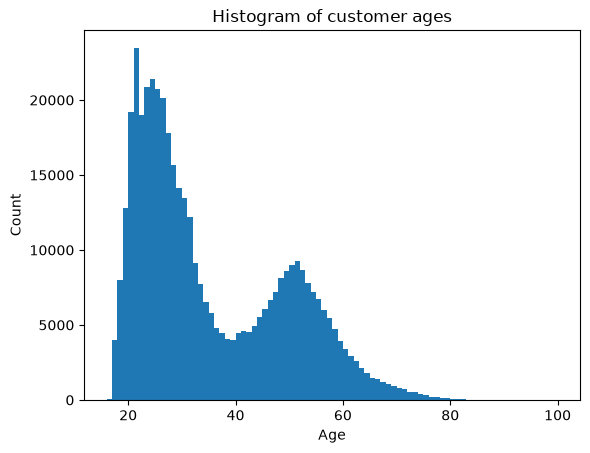

In [11]:
import matplotlib.pyplot as plt
ages = age.dropna()
plt.hist(ages,bins=range(int(ages.min()),int(ages.max())+2))
plt.title('Histogram of customer ages')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

In [12]:
train_customers['club_member_status'].value_counts(dropna=False)

club_member_status
ACTIVE        435619
PRE-CREATE      8177
NaN              585
LEFT CLUB         50
Name: count, dtype: int64

In [13]:
train_customers['fashion_news_frequency'].value_counts(dropna=False)

fashion_news_frequency
NONE         253245
Regularly    189387
NaN            1662
Monthly         137
Name: count, dtype: int64

In [14]:
train_articles = articles[articles['article_id'].isin(train['article_id'])]
print('Train articles:', len(train_articles))

Train articles: 38603


In [15]:
distinct_counts = train_articles.nunique().sort_values(ascending=False)      # yours
print('Distinct counts in train articles:\n', distinct_counts)

Distinct counts in train articles:
 article_id                      38603
prod_name                       19601
product_code                    19354
detail_desc                     18248
department_no                     286
department_name                   238
product_type_no                   123
product_type_name                 122
section_no                         56
section_name                       56
colour_group_name                  50
colour_group_code                  50
graphical_appearance_no            30
graphical_appearance_name          30
garment_group_no                   21
garment_group_name                 21
perceived_colour_master_id         20
perceived_colour_master_name       20
product_group_name                 18
index_code                         10
index_name                         10
perceived_colour_value_id           8
perceived_colour_value_name         8
index_group_name                    5
index_group_no                      5
dtype: int64


## Step 6: Which feature goes in which tower
**Rule:** the two towers never see each other's inputs. Every feature must describe only the customer or only the article, and be known **before** the customer makes a request. That is what lets every article vector be computed once, ahead of time.

| Feature | Tower | Reason |
|---|---|---|
| customer ID (train-only model vocabulary, with an unknown bucket) | User | Known about the customer; built from train weeks only to avoid leakage (not `customer_join_idx`, which is only a join key) |
| age (buckets, see Step 7) | User | Known about the customer before any request |
| club_member_status | User | Known about the customer |
| fashion_news_frequency (spelling normalised) | User | Known about the customer |
| FN (missing = 0) | User | A yes/no flag stored on the customer's profile |
| Active (missing = 0) | User | A yes/no flag stored on the customer's profile |
| postal_code | Not used | Quasi-identifier (privacy), dropped on Day 1 |
| article ID (train-only vocabulary, with an unknown bucket) | Item | Known about the article |
| product_code | Item | Shared by all colours of one design, so a new colour of an existing product (cold `article_id`) still gets a learned signal from its siblings |
| product_type (use `product_type_no`) | Item | Known about the article; the number is safer than the name (123 numbers vs 122 names) |
| product_group_name | Item | Known about the article; broad level above product_type, helps rare types borrow signal |
| graphical_appearance_name | Item | Known about the article |
| colour_group_name | Item | Known about the article |
| perceived_colour_master_name | Item | Known about the article; broad level above colour_group |
| department (use `department_no`) | Item | Known about the article; 286 numbers vs 238 names, so the name would merge different departments |
| index_group_name | Item | Known about the article; broadest level (5 values) |
| section_name | Item | Known about the article |
| garment_group_name | Item | Known about the article |
| median price in train | Item | The transaction `price` is only known after a purchase, but an article's median price over the train weeks is known in advance, so it describes the article |
| price (transaction) | Not used | Describes one purchase, not the article; replaced by median price in train |
| sales_channel_id | Not used in V1 | Describes the visit (online vs store), not the customer or the article; the same person uses both. It could become request-time context in a later version |
| t_dat | Not a feature | Used only to split the data by time |


In [16]:
edges = [16, 20, 25, 30, 40, 50, 60, 100]


In [17]:
age_buckets = pd.cut(train_customers['age'],bins=edges,right=False)
bucket_counts= age_buckets.value_counts(dropna=False).sort_index()
print('Age buckets:\n', bucket_counts)

Age buckets:
 age
[16.0, 20.0)      24829
[20.0, 25.0)     104021
[25.0, 30.0)      88481
[30.0, 40.0)      72165
[40.0, 50.0)      60800
[50.0, 60.0)      68719
[60.0, 100.0)     22987
NaN                2429
Name: count, dtype: int64


In [18]:
assert bucket_counts.sum() == 444431, f'Expected 444431 customers in age buckets, got {bucket_counts.sum()}'
print('All checks passed.')

All checks passed.


In [19]:
def build_vocab(column):
    """Map each distinct value in a training column to a number 1..N (0 is reserved for unknown)."""
    vocab = {}
    # sorted: the same value always gets the same number, run after run
    for number, value in enumerate(sorted(column.dropna().unique()), start=1):
        vocab[value] = number
    return vocab

In [20]:
# Step 8: customer vocabulary, built from train customers only
customer_vocab = build_vocab(train['customer_join_idx'])
print('Customer vocab size:', len(customer_vocab))   # expect 444,431 (Step 2)

Customer vocab size: 444431


In [21]:
assert len(set(customer_vocab.values())) == len(customer_vocab), 'Duplicate numbers in customer vocab'
assert min(customer_vocab.values()) == 1, 'Customer vocab should start at 1'
assert max(customer_vocab.values()) == len(customer_vocab), 'Customer vocab should end at N'

In [22]:
# 3a: each validation customer once
val_customers = val['customer_join_idx'].unique()

In [23]:
# 3b: look up each customer's row number; not in the vocab (cold) -> NaN -> 0 (unknown)
val_customer_number = pd.Series(val_customers).map(customer_vocab).fillna(0)

In [24]:
# 3c: the zeros must be exactly the cold validation customers from Day 4 Step 7
unknown_count = (val_customer_number == 0).sum()
assert unknown_count == 23_512, f'expected 23,512 unknown (cold) validation customers, got {unknown_count:,}'
print('Unknown validation customers:', unknown_count)

Unknown validation customers: 23512


In [25]:
# Step 9: article vocabulary, built from train articles only
article_vocab = build_vocab(train['article_id'])
print('Article vocab size:', len(article_vocab))   # expect 38,603 (Step 5: train articles)

Article vocab size: 38603


In [26]:
assert len(set(article_vocab.values())) == len(article_vocab), 'Duplicate numbers in article vocab'
assert min(article_vocab.values()) == 1, 'Article vocab should start at 1'
assert max(article_vocab.values()) == len(article_vocab), 'Article vocab should end at N'

In [27]:
# 9c: each validation article once, looked up in the vocab; not seen in train -> 0
val_articles = val['article_id'].unique()
val_article_number = pd.Series(val_articles).map(article_vocab).fillna(0)

unknown_articles = (val_article_number == 0).sum()
assert unknown_articles == 1_225, f'expected 1,225 unknown (cold) validation articles, got {unknown_articles:,}'
print('Unknown validation articles:', unknown_articles)

Unknown validation articles: 1225


In [28]:
# Step 10: every category feature from the Step 6 table
article_features = ['product_code', 'product_type_no', 'product_group_name',
                    'graphical_appearance_name', 'colour_group_name',
                    'perceived_colour_master_name', 'department_no',
                    'index_group_name', 'section_name', 'garment_group_name']

customer_features = ['club_member_status', 'fashion_news_frequency']


In [29]:
vocabs = {}   # feature name -> its vocabulary
for name in article_features:
    vocabs[name] = build_vocab(train_articles[name])
for name in customer_features:
    vocabs[name] = build_vocab(train_customers[name])
vocabs['age_bucket'] = build_vocab(age_buckets)


In [30]:
size= {}
for name in vocabs:
    size[name] = len(vocabs[name])

vocab_size = pd.Series(size).sort_values(ascending=False)
vocab_size

product_code                    19354
department_no                     286
product_type_no                   123
section_name                       56
colour_group_name                  50
graphical_appearance_name          30
garment_group_name                 21
perceived_colour_master_name       20
product_group_name                 18
age_bucket                          7
index_group_name                    5
club_member_status                  3
fashion_news_frequency              3
dtype: int64

In [31]:
# Article sizes must match the Step 5 distinct-count table exactly
assert vocab_size['product_code'] == 19_354, f"product_code: expected 19,354, got {vocab_size['product_code']}"
assert vocab_size['product_type_no'] == 123, f"product_type_no: expected 123, got {vocab_size['product_type_no']}"
assert vocab_size['department_no'] == 286, f"department_no: expected 286, got {vocab_size['department_no']}"
assert vocab_size['index_group_name'] == 5, f"index_group_name: expected 5, got {vocab_size['index_group_name']}"

# Age: 7 buckets from Step 7, missing goes to 0
assert vocab_size['age_bucket'] == 7, f"age_bucket: expected 7, got {vocab_size['age_bucket']}"

print('Vocabulary sizes match Step 5 and Step 7.')


Vocabulary sizes match Step 5 and Step 7.


In [32]:
# B1: each train article's median price (from train only, so no leakage)
article_median_price = train.groupby('article_id')['price'].median().reset_index()
article_median_price.columns = ['article_id', 'median_price']

assert len(article_median_price) == 38_603, f'expected one row per train article (38,603), got {len(article_median_price):,}'
print('Articles with a median price:', len(article_median_price))
article_median_price.head()

Articles with a median price: 38603


,article_id,median_price
0,108775015,0.004390
1,108775044,0.008458
2,110065001,0.006424
3,110065002,0.006085
4,110065011,0.009305


In [33]:
# B3: fallback table, median of the article medians within each product type
priced = article_median_price.merge(articles[['article_id', 'product_type_no']], on='article_id')
type_median_price = priced.groupby('product_type_no')['median_price'].median().reset_index()

# last resort for a product type that never sold in train
overall_median_price = article_median_price['median_price'].median()

print('Product types in the fallback table:', len(type_median_price))
print('Overall median price:', overall_median_price)
assert len(type_median_price) == vocab_size['product_type_no'], 'fallback should cover every train product type'

Product types in the fallback table: 123
Overall median price: 0.021169491


In [34]:
import os
import json

FEATURES_FOLDER = '../data/processed/features'
os.makedirs(FEATURES_FOLDER, exist_ok=True)

def save_vocab(vocab, name):
    """Save a vocabulary as a 2-column parquet table: value, index."""
    table = pd.DataFrame({'value': list(vocab.keys()), 'index': list(vocab.values())})
    table.to_parquet(f'{FEATURES_FOLDER}/vocab_{name}.parquet', index=False)

save_vocab(customer_vocab, 'customer')
save_vocab(article_vocab, 'article')

for name in vocabs:
    if name == 'age_bucket':
        # store each bucket by its left edge (an int), since parquet can't hold Interval objects
        left_edges = {bucket.left: number for bucket, number in vocabs[name].items()}
        save_vocab(left_edges, name)
    else:
        save_vocab(vocabs[name], name)

article_median_price.to_parquet(f'{FEATURES_FOLDER}/article_median_price.parquet', index=False)
type_median_price.to_parquet(f'{FEATURES_FOLDER}/type_median_price.parquet', index=False)

# small settings: plain numbers and a list, no number keys, so JSON is safe here
with open(f'{FEATURES_FOLDER}/settings.json', 'w') as f:
    json.dump({'overall_median_price': float(overall_median_price), 'age_edges': edges}, f, indent=2)

print(sorted(os.listdir(FEATURES_FOLDER)))

['article_median_price.parquet', 'settings.json', 'type_median_price.parquet', 'vocab_age_bucket.parquet', 'vocab_article.parquet', 'vocab_club_member_status.parquet', 'vocab_colour_group_name.parquet', 'vocab_customer.parquet', 'vocab_department_no.parquet', 'vocab_fashion_news_frequency.parquet', 'vocab_garment_group_name.parquet', 'vocab_graphical_appearance_name.parquet', 'vocab_index_group_name.parquet', 'vocab_perceived_colour_master_name.parquet', 'vocab_product_code.parquet', 'vocab_product_group_name.parquet', 'vocab_product_type_no.parquet', 'vocab_section_name.parquet']


## D (Step 12): Reload and prove it

In [35]:
def load_vocab(name):
    """Load a saved vocabulary back into a dictionary."""
    table = pd.read_parquet(f'{FEATURES_FOLDER}/vocab_{name}.parquet')
    return dict(zip(table['value'], table['index']))

customer_vocab_loaded = load_vocab('customer')
article_vocab_loaded = load_vocab('article')

# sizes and 1..N range unchanged
for name, original, loaded in [('customer', customer_vocab, customer_vocab_loaded),
                               ('article', article_vocab, article_vocab_loaded)]:
    assert len(loaded) == len(original), f'{name}: size changed {len(original):,} -> {len(loaded):,}'
    assert min(loaded.values()) == 1, f'{name}: should start at 1'
    assert max(loaded.values()) == len(loaded), f'{name}: should end at N'

for name in vocabs:
    loaded = load_vocab(name)
    assert len(loaded) == len(vocabs[name]), f'{name}: size changed'
    assert min(loaded.values()) == 1 and max(loaded.values()) == len(loaded), f'{name}: not 1..N'

print('Sizes and ranges unchanged.')

Sizes and ranges unchanged.


In [36]:
# The real check: the RELOADED mappings must still find the same people and articles.
# (This is the assert that would catch the JSON number-to-text trap.)
val_customer_zeros = (pd.Series(val['customer_join_idx'].unique()).map(customer_vocab_loaded).fillna(0) == 0).sum()
val_article_zeros = (pd.Series(val['article_id'].unique()).map(article_vocab_loaded).fillna(0) == 0).sum()

assert val_customer_zeros == 23_512, f'expected 23,512 unknown validation customers, got {val_customer_zeros:,}'
assert val_article_zeros == 1_225, f'expected 1,225 unknown validation articles, got {val_article_zeros:,}'

# prices and settings came back too
assert len(pd.read_parquet(f'{FEATURES_FOLDER}/article_median_price.parquet')) == 38_603
assert len(pd.read_parquet(f'{FEATURES_FOLDER}/type_median_price.parquet')) == len(type_median_price)
with open(f'{FEATURES_FOLDER}/settings.json') as f:
    settings = json.load(f)
assert settings['age_edges'] == edges

print('Reloaded customer zeros:', val_customer_zeros, '| article zeros:', val_article_zeros)
print('Everything reloads correctly.')

Reloaded customer zeros: 23512 | article zeros: 1225
Everything reloads correctly.


## Day 5 interview question
*"Your item tower can't see anything about the customer. Why is that a strength of the design rather than a limitation?"*

> Because the item tower only depends on the article, I can compute every article's vector once, ahead of time, and store it in an index. When a customer arrives, I only run the user tower and do a fast nearest-neighbour search against those stored vectors, instead of running a model on every customer-article pair. That's what makes it fast enough to rank tens of thousands of articles in milliseconds. The customer-article interaction isn't lost: it's captured by the dot product, and a heavier ranking model can look at both together later, on a short list.